# Tutorial 2: Kidney training and prediction

This tutorial trains TxCellNet on the two kidney cancer sections of the 10x Genomics Xenium Protein datasets, which measure
RNA and 27 proteins in the same section: a renal cell carcinoma (RCC) and a clear cell renal cell carcinoma (ccRCC). Each
section is cut into eight vertical stripes with equal numbers of cells; the networks train on stripes 1, 3, 5 and 7 and are
scored on stripes 2, 4, 6 and 8 (counted from the left), as in the paper. The steps follow the commands of the README:

1. prepare the training grids, the stripe split and the evaluation cells;
2. train one clean stage-1 network on the training stripes of both sections (the paper's network `fin_clean_s1`);
3. predict the held-out stripes and compute the cell-level Spearman correlation of every protein, next to the paper's values;
4. train stage 2 on the stage-1 images of this network;
5. refine a held-out window and compare the measured, stage-1 and stage-2 images.

The run needs a CUDA GPU and takes several hours; the last cell lists the time of each step. The outputs below come from one
run of this notebook.

**Demo settings.** To finish in about 1.5 hours on one GPU (much of it reading the data and evaluating stage 2), this notebook trains stage 1 for 3,000 iterations and stage 2 for 2,000, instead of the paper's 24,000 and 30,000, and evaluates stage 2 at the paper's noise scale 0.85 only. The accuracies are therefore below the paper's. To reproduce the paper, set `ITERS1 = 24000` and `ITERS2 = 30000` in the setup cell (about 8 hours).


## Data

The two sections are public on the 10x Genomics website:
[RCC](https://www.10xgenomics.com/datasets/xenium-protein-ffpe-human-renal-carcinoma)
(`Xenium_V1_Human_Kidney_FFPE_Protein_updated`) and
[ccRCC](https://www.10xgenomics.com/datasets/xenium-protein-ffpe-human-renal-ccrcc)
(`Xenium_V1_Human_Clear_Cell_Renal_Cell_Carcinoma_FFPE_Protein`). Each output bundle is one zip file (36 GB and 57 GB). The
scripts read only the files unpacked below, so the large 3D morphology image can stay in the archive. From the repository
root:

```bash
B=https://s3-us-west-2.amazonaws.com/10x.files/samples/xenium/4.0.0
RCC=Xenium_V1_Human_Kidney_FFPE_Protein_updated
CCRCC=Xenium_V1_Human_Clear_Cell_Renal_Cell_Carcinoma_FFPE_Protein
wget $B/$RCC/${RCC}_outs.zip $B/$CCRCC/${CCRCC}_outs.zip
FILES="transcripts.parquet cells.parquet cell_boundaries.parquet cell_feature_matrix.h5 gene_panel.json"
unzip ${RCC}_outs.zip 'morphology_focus/*' $FILES -d data/xenium_protein_rcc/outs
unzip ${CCRCC}_outs.zip 'morphology_focus/*' $FILES -d data/xenium_protein_ccrcc/outs
```

## Setup

Run the notebook in a clone of the repository with TxCellNet installed (see Installation). The cell below moves to the
repository root, because the scripts read `data/` and write `results/` relative to it, and puts the kernel's Python first on
the `PATH`, so that `!python` runs the scripts in the same environment. Choose the GPU by setting `CUDA_VISIBLE_DEVICES`
before starting Jupyter. `ok()` stops the notebook when a shell command fails.

In [1]:
import os
for v in ('OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'OPENBLAS_NUM_THREADS'):
    os.environ.setdefault(v, '16')  # before NumPy loads: too many BLAS threads can crash on hosts with many cores
import sys, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'txcellnet' / '__init__.py').exists())
os.chdir(REPO)  # the scripts read data/ and write results/ relative to the repository root
os.environ['PATH'] = os.path.dirname(sys.executable) + os.pathsep + os.environ['PATH']  # `!python` = this kernel's Python

import txcellnet

RUN, REFINE = 'tut_clean_s1', 'tut_refine'  # names of the stage-1 and stage-2 runs
SD = {'rcc': 'data/xenium_protein_rcc/pilot_L2', 'ccrcc': 'data/xenium_protein_ccrcc/pilot_L2'}  # training grids
TIMES = {}  # wall time of each step


def ok():
    '''stop the notebook if the last shell command failed'''
    if _exit_code != 0:
        raise RuntimeError(f'the last shell command exited with status {_exit_code}')


%matplotlib inline
%config InlineBackend.figure_formats = ['jpeg']
plt.rcParams.update({'figure.dpi': 100, 'image.interpolation': 'nearest'})
print('repository:', REPO.name)
print('txcellnet', txcellnet.__version__, 'from', Path(txcellnet.__file__).parent.relative_to(REPO))
print('torch', torch.__version__, '| GPU:', torch.cuda.get_device_name(0))

# demo settings; the paper uses ITERS1 = 24000 (stage 1) and ITERS2 = 30000 (stage 2)
ITERS1, ITERS2 = 3000, 2000


repository: txcellnet_tutorial
txcellnet 1.0.0 from txcellnet
torch 2.5.1+cu121 | GPU: NVIDIA H100 80GB HBM3


In [2]:
# the input files of each section
FILES = ['transcripts.parquet', 'cells.parquet', 'cell_boundaries.parquet', 'cell_feature_matrix.h5', 'gene_panel.json']
for s in SD:
    outs = Path(f'data/xenium_protein_{s}/outs')
    tifs = sorted((outs / 'morphology_focus').glob('*.ome.tif'))
    print(f'{s}:', ', '.join(f'{f} {os.path.getsize(outs / f) / 1e9:.2f} GB' for f in FILES),
          f'| morphology_focus: {len(tifs)} images, {sum(os.path.getsize(t) for t in tifs) / 1e9:.1f} GB')

rcc: transcripts.parquet 1.02 GB, cells.parquet 0.01 GB, cell_boundaries.parquet 0.04 GB, cell_feature_matrix.h5 0.03 GB, gene_panel.json 0.00 GB | morphology_focus: 35 images, 17.1 GB


ccrcc: transcripts.parquet 1.02 GB, cells.parquet 0.01 GB, cell_boundaries.parquet 0.06 GB, cell_feature_matrix.h5 0.05 GB, gene_panel.json 0.00 GB | morphology_focus: 35 images, 27.3 GB


## Prepare the data

`prep_kidney_grid.py` reads pyramid level 2 of the morphology images (0.85 µm per pixel) and writes the training grid of a
section to `data/xenium_protein_<s>/pilot_L2`: log DAPI, the 27 protein images as log1p(max(x − 100, 0)), a mask of valid
pixels, a tissue mask and the cell labels rasterized from the cell boundaries. `prep_kidney_tx.py` places the transcripts
(quality ≥ 20) on the same grid. `make_kidney_splits.py` cuts each section into the eight stripes and stores the 10x per-cell
protein values of the held-out cells, against which `train_gen.py` reports its Pearson correlation.

The `p99 nan` values and the overflow warnings in the log come from a diagnostic print (a percentile of a float16 array under
NumPy 2); the saved images are not affected (see the table further down).

In [3]:
t0 = time.time()
for s in SD:
    !python scripts/data/prep_kidney_grid.py xenium_protein_{s}
    ok()
    !python scripts/data/prep_kidney_tx.py data/xenium_protein_{s}/pilot_L2
    ok()
!python scripts/data/make_kidney_splits.py
ok()
TIMES['training grids and split'] = time.time() - t0

00:56:59 reading DAPI


00:57:00 grid 6832 13500 um/px 0.85


00:57:04 protein PD-1 ch0019_pd-1.ome.tif p99 2.564453125


00:57:07 protein VISTA ch0020_vista.ome.tif p99 3.21875


00:57:11 protein PD-L1 ch0021_pd-l1.ome.tif p99 1.38671875


...

01:05:16 rasterising cells


01:08:44 saved data/xenium_protein_ccrcc/pilot_L2


transcripts 65480008 genes 477 blocks 45368 nuclear frac 0.434


rcc cells 453618 / 465534 held out 226809 proteins 27


ccrcc cells 630355 / 690322 held out 315177 proteins 27


The evaluation uses the paper's benchmark format (`data/cases/kidney_<s>`), which every compared method reads.
`prep_case_xenium.py` writes the DAPI, cell labels, transcripts and gene counts of a section on the same grid,
`add_kidney_eval.py` marks the cells of the held-out stripes, and `add_kidney_protein_truth.py` adds the truth of each
protein: the per-cell mean of the measured image log1p(max(x − 100, 0)). The arguments after the output folder are the
section name, a tissue label and a panel label (labels only; see `data/README.md`).

In [4]:
t0 = time.time()
!python scripts/data/prep_case_xenium.py data/xenium_protein_rcc/outs data/cases/kidney_rcc kidney_rcc kidney_RCC v1_377+28
ok()
!python scripts/data/prep_case_xenium.py data/xenium_protein_ccrcc/outs data/cases/kidney_ccrcc kidney_ccrcc kidney_ccRCC v1_377+100
ok()
!python scripts/data/add_kidney_eval.py
ok()
!python scripts/data/add_kidney_protein_truth.py
ok()
TIMES['evaluation cells'] = time.time() - t0

01:09:21 kidney_rcc reading morphology_focus level 2


01:09:26 boundary ch0001_atp1a1_cd45_e-cadherin.ome.tif p50/p99 20.0 162.0


01:09:30 rna18s ch0002_18s.ome.tif p50/p99 13.0 131.0


01:09:34 interior ch0003_alphasma_vimentin.ome.tif p50/p99 6.0 164.0


01:10:23 transcripts qv>=20 62948437 in model vocab 62948437 (100.0%) panel genes 405 vocab genes present 405 of 495


...

01:13:24 saved data/cases/kidney_ccrcc


rcc test-stripe cells 233251 of 465534


ccrcc test-stripe cells 344780 of 690322


rcc added 27 protein markers


ccrcc added 27 protein markers


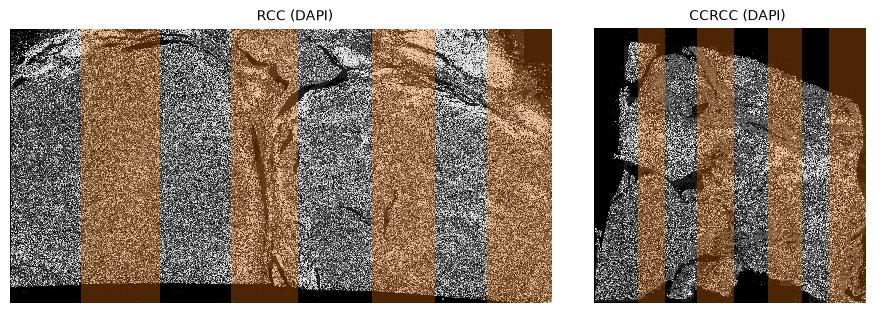

,rcc,ccrcc
grid (px),6832 x 13500,13633 x 13514
genes in panel,405,477
proteins,27,27
transcripts (q >= 20),62948437,65480008
cells,465534,690322
cells in held-out stripes,233251,344780
"E-cadherin image, 99th percentile",2.945,3.912


In [5]:
# the prepared sections; the held-out stripes are shaded
METAS = {s: json.load(open(f'{sd}/meta.json')) for s, sd in SD.items()}
fig, axes = plt.subplots(1, 2, figsize=(9, 3.1), gridspec_kw=dict(width_ratios=[m['W'] / m['H'] for m in METAS.values()]))
summary = {}
for ax, (s, sd) in zip(axes, SD.items()):
    meta = METAS[s]
    edges = np.array(json.load(open(f'results/cell_baseline/{s}_stripes.json'))['x_edges_um']) / meta['um_per_px']
    cells = pd.read_parquet(f'data/cases/kidney_{s}/cells.parquet')
    Y = np.load(f'{sd}/Y.npy', mmap_mode='r')
    ecad = np.asarray(Y[meta['prots'].index('E-Cadherin'), ::8, ::8], np.float32)
    summary[s] = {'grid (px)': f"{meta['H']} x {meta['W']}", 'genes in panel': len(meta['genes']),
                  'proteins': len(meta['prots']), 'transcripts (q >= 20)': len(np.load(f'{sd}/tx.npz')['gid']),
                  'cells': len(cells), 'cells in held-out stripes': int(cells['test_stripe'].sum()),
                  'E-cadherin image, 99th percentile': round(float(np.percentile(ecad, 99)), 3)}
    dapi = np.asarray(np.load(f'{sd}/X.npy', mmap_mode='r')[0, ::16, ::16], np.float32)
    ax.imshow(dapi, cmap='gray', vmin=np.percentile(dapi, 1), vmax=np.percentile(dapi, 99.5))
    for k, (a, b) in enumerate(zip([0, *edges], [*edges, meta['W']])):
        if k % 2 == 1:
            ax.axvspan(a / 16, b / 16, color='tab:orange', alpha=0.3, lw=0)
    ax.set_title(f'{s.upper()} (DAPI)', fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()
pd.DataFrame(summary)

## Stage 1: train one clean network

`train_gen.py` trains one network on 256-px patches drawn from the training stripes of both sections (batches of 16; 24,000
iterations in the paper, `ITERS1` here, AdamW with a one-cycle learning rate of 1e-3, exponential moving average of the weights). The command is the one
of the paper's clean network `fin_clean_s1`, seed 1: with `PAUG=0` no patch is randomized, and `THIN`, `GDROP` and `DAUG` set
the randomization (molecule thinning, gene dropout, DAPI perturbation) that the randomized networks (`PAUG=1`) apply. At the
end the script predicts both sections and logs the cell-level Pearson correlation on the held-out stripes against the 10x
per-cell protein values. The weights and the configuration are saved in `runs/tut_clean_s1` of both training grids.

In [6]:
t0 = time.time()
!PAUG=0 THIN=1 GDROP=0.5 DAUG=1 SEED=1 python scripts/train/train_gen.py {RUN} {ITERS1}
ok()
TIMES['stage 1 training'] = time.time() - t0

01:19:44 cfg {'rep': 'learned', 'enc': 'sum', 'own': 0, 'thin': 1, 'gdrop': 0.5, 'daug': 1, 'seed': 1, 'iters': 3000, 'paug': 0.0, 'nodapi': 0, 'noniche': 0, 'pcaemb': 0}; union genes 495, model vocab 495, genes read 495


01:22:11 loaded; train px [41946233, 63485592]


01:27:58 it 2000 loss 0.6082 0.170s/it


01:31:34 rcc held-out stripes cell-level Pearson median 0.717 mean 0.699


01:32:57 ccrcc held-out stripes cell-level Pearson median 0.733 mean 0.7
01:32:57 done


## Score every protein on the held-out stripes

The kidney columns of Fig. 2b and Supplementary Table S13 of the paper were computed by `scripts/benchmark/run_bench_gen.py`,
which also scores the two stain channels of the multimodal segmentation and reads the panel groups and stain weights of the
full benchmark. The cell below repeats its steps for the 27 proteins: `predict_case` predicts the whole section (windows of up
to 1024 px with 64-px margins, four flips averaged), the mean of the predicted image over a cell's pixels is the cell's
prediction, and `metrics` compares it with the per-cell mean of the measured image on the scored cells: the cells of the
held-out stripes with at least 10 pixels and one transcript.

In [7]:
from txcellnet import GenNet, predict_case, metrics, label_counts, load_case_image
from txcellnet.bench import PROTS, OWN

t0 = time.time()
c = json.load(open(f'{SD["rcc"]}/runs/{RUN}/cfg.json'))
net = GenNet(PROTS, OWN, c['cfg'], c['train_genes']).cuda()
net.load_state_dict(torch.load(f'{SD["rcc"]}/runs/{RUN}/model.pt', map_location='cuda', weights_only=True), strict=False)
net.eval()
vocab = net.prepare(c['train_genes'])  # genes the network reads

scores = []
for s in SD:
    case = load_case_image(f'data/cases/kidney_{s}')
    cells, meta = case['cells'], case['meta']
    csum, n_read, n_total, _ = predict_case(net, vocab, case)
    pred = (csum / np.maximum(label_counts(case['lab']), 1)[:, None])[cells['label'].values]  # per-cell means
    scored = (cells['area_px'].values >= 10) & (cells['total_counts'].values >= 1) & cells[meta['eval_mask']].values
    for j, p in enumerate(PROTS):
        truth = cells[meta['markers'][p]['truth']].values  # per-cell mean of the measured image
        scores.append(dict(section=s, protein=p, **metrics(pred[scored, j], truth[scored]), cells=int(scored.sum())))
    print(f'{s}: molecules read {n_read:,} of {n_total:,}; scored cells {scored.sum():,}')
scores = pd.DataFrame(scores)
del net
torch.cuda.empty_cache()
TIMES['held-out prediction and scoring'] = time.time() - t0

rcc: molecules read 62,948,437 of 62,948,437; scored cells 233,023


ccrcc: molecules read 65,480,008 of 65,480,008; scored cells 342,303


In [8]:
# kidney column 'TxC' of Supplementary Table S13: the paper's network fin_clean_s1, mean of the two sections
PAPER = {'CD20': 0.53, 'CD3E': 0.88, 'CD4': 0.77, 'CD8A': 0.80, 'CD45': 0.92, 'CD45RO': 0.86, 'CD45RA': 0.65, 'CD68': 0.83,
         'CD163': 0.72, 'CD11c': 0.69, 'CD16': 0.69, 'CD138': 0.55, 'PanCK': 0.66, 'E-Cadherin': 0.72, 'Beta-catenin': 0.70,
         'Vimentin': 0.70, 'alphaSMA': 0.68, 'CD31': 0.76, 'Ki-67': 0.56, 'PCNA': 0.74, 'PD-1': 0.61, 'PD-L1': 0.49,
         'LAG-3': 0.57, 'VISTA': 0.71, 'GranzymeB': 0.34, 'HLA-DR': 0.85, 'PTEN': 0.77}
assert sorted(PAPER) == sorted(PROTS)
tab = scores.pivot(index='protein', columns='section', values='spearman').loc[list(PAPER), ['rcc', 'ccrcc']]
tab['mean'] = tab[['rcc', 'ccrcc']].mean(1)
tab['paper (Table S13)'] = pd.Series(PAPER)
tab['difference'] = tab['mean'] - tab['paper (Table S13)']
print('cell-level Spearman, held-out stripes; median over the 27 proteins:',
      ', '.join(f'{k} {v:.3f}' for k, v in tab.median().items() if k != 'difference'))
tab.round(2)

cell-level Spearman, held-out stripes; median over the 27 proteins: rcc 0.659, ccrcc 0.682, mean 0.666, paper (Table S13) 0.700


section,rcc,ccrcc,mean,paper (Table S13),difference
protein,,,,,
CD20,0.52,0.53,0.52,0.53,-0.01
CD3E,0.85,0.87,0.86,0.88,-0.02
CD4,0.76,0.74,0.75,0.77,-0.02
CD8A,0.78,0.78,0.78,0.80,-0.02
CD45,0.88,0.91,0.90,0.92,-0.02
CD45RO,0.81,0.88,0.84,0.86,-0.02
CD45RA,0.70,0.58,0.64,0.65,-0.01
CD68,0.85,0.77,0.81,0.83,-0.02
CD163,0.81,0.59,0.70,0.72,-0.02


Proteins are listed in the order of the paper's table (immune lineage, epithelial, stromal and vascular, cell state and
checkpoint). The paper's column is the network `fin_clean_s1`, trained with the same command for 24,000 iterations; scoring that network
with the cell above reproduces the table to two decimals. The demo network is trained for `ITERS1` iterations only, so its
values are lower.

## Stage 2: train the residual flow

Stage 2 adds the sub-cellular texture that the conditional mean averages out. `pred_kidney_full.py` predicts the whole grid of
both sections with the stage-1 network (training and held-out stripes) and saves it as `pred_full.npy` in the run folder.
`train_refine.py` trains the residual rectified flow on the training stripes (30,000 iterations in the paper, `ITERS2` here),
conditioned on the stage-1 image, DAPI and cell geometry, and evaluates it on the held-out stripes at the noise scale 0.85 (the paper also
reports 1.0). In the paper, stage 2 is conditioned on the mean image of the six-network ensemble (`fin_ens6`, three clean and
three randomized networks); here it is conditioned on the single network trained above.

In [9]:
t0 = time.time()
!python scripts/train/pred_kidney_full.py {RUN} {RUN}
ok()
TIMES['stage 1, whole grids'] = time.time() - t0
t0 = time.time()
!ITERS={ITERS2} NOISES=0.85 python scripts/train/train_refine.py {RUN} {REFINE}
ok()
TIMES['stage 2 training and evaluation'] = time.time() - t0

rcc saved (27, 6832, 13500)


ccrcc saved (27, 13633, 13514)


01:47:09 mean=tut_clean_s1; residual SD per protein (z units) median 0.769; train windows [636468, 990027]


02:06:10 it 2000 loss 0.9447 0.564s/it


02:13:09 rcc noise 0.85
                                 cell_r  pix_r  within_r  sharp  hfpow     sd     W1
method                config                                                        
mean (stage 1)        -           0.717  0.598     0.419  0.391  0.060  0.581  0.279
refined (constrained) noise0.85   0.717  0.420     0.212  2.175  1.347  0.906  0.394
refined (raw)         noise0.85   0.638  0.416     0.212  2.186  1.339  0.922  0.410


02:29:49 ccrcc noise 0.85
                                 cell_r  pix_r  within_r  sharp  hfpow     sd     W1
method                config                                                        
mean (stage 1)        -           0.733  0.641     0.364  0.436  0.076  0.593  0.263
refined (constrained) noise0.85   0.733  0.442     0.158  2.998  1.348  0.890  0.420
refined (raw)         noise0.85   0.654  0.462     0.158  3.001  1.328  0.916  0.418


02:29:49 ALL (median over proteins)
                                         cell_r  pix_r  within_r  sharp  hfpow     sd     W1
section method                config                                                        
ccrcc   mean (stage 1)        -           0.733  0.641     0.364  0.436  0.076  0.593  0.263
        refined (constrained) noise0.85   0.733  0.442     0.158  2.998  1.348  0.890  0.420
        refined (raw)         noise0.85   0.654  0.462     0.158  3.001  1.328  0.916  0.418
rcc     mean (stage 1)        -           0.717  0.598     0.419  0.391  0.060  0.581  0.279
        refined (constrained) noise0.85   0.717  0.420     0.212  2.175  1.347  0.906  0.394
        refined (raw)         noise0.85   0.638  0.416     0.212  2.186  1.339  0.922  0.410


The table gives medians over the 27 proteins at noise scale 0.85 (the paper's setting). `cell_r` is the cell-level Pearson
correlation with the 10x per-cell values, `pix_r` the pixel correlation with the measured image and `within_r` the
correlation of the deviations from the cell mean (the sub-cellular pattern). `sharp` (mean absolute gradient), `hfpow`
(power above 0.2 cycles per pixel) and `sd` (pixel SD) are ratios to the measured image, so 1 matches it, and `W1` is the
1-Wasserstein distance between the pixel values of the image and of the measured image (z units). `refined (constrained)` is
the stage-2 image, whose sampled residual has its mean removed in every cell; `refined (raw)` is the sample before that step.

In [10]:
m = pd.read_csv(f'{SD["rcc"]}/runs/{REFINE}/metrics.csv')
m = m[(m.method == 'mean (stage 1)') | (m.config == 'noise0.85')]
stage2 = m.groupby(['section', 'method'])[['cell_r', 'pix_r', 'within_r', 'sharp', 'hfpow', 'sd', 'W1']].median()
stage2.round(3)

cell_r  pix_r  within_r  sharp  hfpow     sd  \
section method                                                                
ccrcc   mean (stage 1)          0.733  0.641     0.364  0.436  0.076  0.593   
        refined (constrained)   0.733  0.442     0.158  2.998  1.348  0.890   
        refined (raw)           0.654  0.462     0.158  3.001  1.328  0.916   
rcc     mean (stage 1)          0.717  0.598     0.419  0.391  0.060  0.581   
        refined (constrained)   0.717  0.420     0.212  2.175  1.347  0.906   
        refined (raw)           0.638  0.416     0.212  2.186  1.339  0.922   

                                  W1  
section method                        
ccrcc   mean (stage 1)         0.263  
        refined (constrained)  0.420  
        refined (raw)          0.418  
rcc     mean (stage 1)         0.279  
        refined (constrained)  0.394  
        refined (raw)          0.410

With only `ITERS2` = 2,000 iterations, stage 2 overshoots: its images are sharper and richer in high frequencies than the
measured image (`sharp` and `hfpow` above 1). With the paper's 30,000 iterations, conditioned on the six-network ensemble, the
same ratios are 1.04--1.06 and 0.65--0.72 on these stripes (Supplementary Section S3). The cell-level correlation `cell_r` of the
constrained stage-2 image equals that of stage 1, because stage 2 keeps every cell mean.


## Refine a held-out window

`crops_kidney.py`, the script behind the image windows of the paper, picks a 240 × 240 px window (204 µm) inside a held-out
stripe of the RCC section that contains epithelium, immune cells and stroma (chosen from the measured image only), and saves
the measured and stage-1 images of the window with its cell labels. `load_refiner` loads the stage-2 network, and `refine` samples a residual for the window (Euler
steps from noise scaled by 0.85), sets it to zero outside the tissue and removes its mean in every cell, so each cell keeps
its stage-1 value. Stage 2 reads DAPI z-scored with the statistics of the training stripes, as in `train_refine.py`.

In [11]:
from txcellnet import load_refiner, refine

t0 = time.time()
os.makedirs('results/tutorial', exist_ok=True)
!python scripts/figdata/crops_kidney.py rcc {RUN} {REFINE} results/tutorial/crops_rcc.npz 240
ok()
w = np.load('results/tutorial/crops_rcc.npz')
y0, x0, Z = (int(v) for v in w['window'])
sl = (slice(y0, y0 + Z), slice(x0, x0 + Z))
sd, meta = SD['rcc'], METAS['rcc']

# DAPI as stage 2 reads it (train_refine.py): log DAPI z-scored with 2,000,000 pixels of the training stripes
valid, tissue = np.load(f'{sd}/valid.npy'), np.load(f'{sd}/tissue.npy')
edges = np.array(json.load(open('results/cell_baseline/rcc_stripes.json'))['x_edges_um']) / meta['um_per_px']
fit = valid & tissue & ~(np.digitize(np.arange(valid.shape[1]), edges) % 2 == 1)[None, :]
ii = np.flatnonzero(fit.ravel())[np.random.default_rng(0).choice(int(fit.sum()), 2_000_000)]
X0 = np.asarray(np.load(f'{sd}/X.npy', mmap_mode='r')[0], np.float32)
v = X0.ravel()[ii]
dapi = ((X0[sl] - v.mean()) / (v.std() + 1e-4)).astype(np.float16).astype(np.float32)
del X0

flow, rsd, steps = load_refiner(f'{sd}/runs/{REFINE}')
mu, lab, measured = w['mean'], w['lab'], w['measured']  # stage 1 (z units), cell labels, measured log1p image
refined = refine(flow, rsd, mu, dapi, lab, inside=(valid & tissue)[sl], noise=0.85, steps=steps)
TIMES['window refinement'] = time.time() - t0

# every cell keeps its stage-1 mean
lr = lab.ravel()
n_px = np.bincount(lr)
cells_in = np.flatnonzero(n_px[1:]) + 1
cell_mean = lambda img: np.stack([np.bincount(lr, weights=ch.ravel().astype(np.float64), minlength=len(n_px))[cells_in]
                                  / n_px[cells_in] for ch in img])
max_diff = np.abs(cell_mean(refined) - cell_mean(mu)).max()
print(f'window: rows {y0}-{y0 + Z}, columns {x0}-{x0 + Z} ({Z * meta["um_per_px"]:.0f} µm), {len(cells_in)} cells')
print(f'largest change of a cell mean by stage 2: {max_diff:.1e} (z units)')

window 5392 6800 score 0.35


saved results/tutorial/crops_rcc.npz


window: rows 5392-5632, columns 6800-7040 (204 µm), 580 cells
largest change of a cell mean by stage 2: 6.7e-08 (z units)


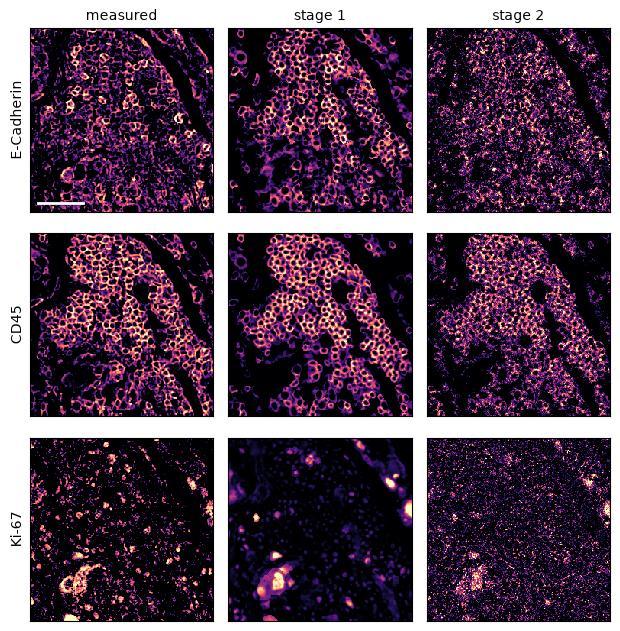

In [12]:
SHOW = ['E-Cadherin', 'CD45', 'Ki-67']
prots = list(w['prots'])
fig, axes = plt.subplots(len(SHOW), 3, figsize=(6.3, 6.5))
for i, p in enumerate(SHOW):
    for k, (name, img) in enumerate([('measured', measured), ('stage 1', mu), ('stage 2', refined)]):
        a = img[prots.index(p)]
        ax = axes[i, k]
        ax.imshow(a, cmap='magma', vmin=np.percentile(a, 50), vmax=np.percentile(a, 99.5))
        ax.set_xticks([])
        ax.set_yticks([])
        if i == 0:
            ax.set_title(name, fontsize=10)
        if k == 0:
            ax.set_ylabel(p, fontsize=10)
axes[0, 0].plot([10, 10 + 50 / meta['um_per_px']], [Z - 12, Z - 12], color='white', lw=2)  # 50 µm
plt.tight_layout()
plt.show()

Each panel is scaled from its median to its 99.5th percentile (scale bar 50 µm). The measured image is log1p of the measured
intensity; the stage-1 and stage-2 images are in the networks' units (per-section z-scored log1p intensity). Stage 1 is the
conditional mean, smooth within cells; stage 2 adds sub-cellular texture and keeps every cell's stage-1 value.

## Summary

In [13]:
print('Stage 1, held-out stripes, cell-level Spearman (27 proteins)')
for s in SD:
    print(f'  {s:5s}  median {tab[s].median():.3f}, mean {tab[s].mean():.3f}')
d = tab['difference']
print(f"  mean of the two sections: median {tab['mean'].median():.3f} (Table S13 values: {tab['paper (Table S13)'].median():.3f}); "
      f'difference per protein {d.min():+.2f} to {d.max():+.2f}')
print('  highest:', ', '.join(f'{p} {v:.2f}' for p, v in tab['mean'].nlargest(3).items()),
      '| lowest:', ', '.join(f'{p} {v:.2f}' for p, v in tab['mean'].nsmallest(3).items()))
print('Stage 2, held-out stripes, medians over proteins (noise 0.85; sharp and hfpow of the measured image = 1)')
for s in SD:
    a, b = stage2.loc[(s, 'mean (stage 1)')], stage2.loc[(s, 'refined (constrained)')]
    print(f'  {s:5s}  stage 1 -> stage 2: cell_r {a.cell_r:.3f} -> {b.cell_r:.3f}, sharp {a.sharp:.2f} -> {b.sharp:.2f}, '
          f'hfpow {a.hfpow:.2f} -> {b.hfpow:.2f}, within_r {a.within_r:.2f} -> {b.within_r:.2f}')
print(f'Window: {len(cells_in)} cells, largest change of a cell mean by stage 2 {max_diff:.1e}')
print('Wall time per step')
for k, v in TIMES.items():
    print(f'  {k:34s} {v / 3600:5.2f} h')
print(f'  {"total":34s} {sum(TIMES.values()) / 3600:5.2f} h')
print('Disk use of the outputs')
!du -sh data/xenium_protein_rcc/pilot_L2 data/xenium_protein_ccrcc/pilot_L2 data/cases results

Stage 1, held-out stripes, cell-level Spearman (27 proteins)
  rcc    median 0.659, mean 0.672
  ccrcc  median 0.682, mean 0.650
  mean of the two sections: median 0.666 (Table S13 values: 0.700); difference per protein -0.08 to +0.01
  highest: CD45 0.90, CD3E 0.86, CD45RO 0.84 | lowest: GranzymeB 0.35, PD-L1 0.42, Ki-67 0.52
Stage 2, held-out stripes, medians over proteins (noise 0.85; sharp and hfpow of the measured image = 1)
  rcc    stage 1 -> stage 2: cell_r 0.717 -> 0.717, sharp 0.39 -> 2.17, hfpow 0.06 -> 1.35, within_r 0.42 -> 0.21
  ccrcc  stage 1 -> stage 2: cell_r 0.733 -> 0.733, sharp 0.44 -> 3.00, hfpow 0.08 -> 1.35, within_r 0.36 -> 0.16
Window: 580 cells, largest change of a cell mean by stage 2 6.7e-08
Wall time per step
  training grids and split            0.21 h
  evaluation cells                    0.17 h
  stage 1 training                    0.22 h
  held-out prediction and scoring     0.05 h
  stage 1, whole grids                0.11 h
  stage 2 training and eva

16G	data/xenium_protein_rcc/pilot_L2


30G	data/xenium_protein_ccrcc/pilot_L2


3.6G	data/cases


22M	results
